# COVID-19 Early Case Trend Analysis and Recovery Insights

This notebook reproduces the descriptive analysis in `Project_Report.docx`. It reads the included `patient.csv` file and writes figures to `figures/`. The file is an early South Korea case snapshot, with confirmation dates from 20 January to 1 March 2020. Many fields are missing, so results must be interpreted as summaries of recorded values only.

## 1. Setup and load the data

Install the packages in `requirements.txt` if needed. Keep this notebook in the same folder as `patient.csv`, then run all cells from top to bottom.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from IPython.display import display

DATA_PATH = Path('patient.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Place patient.csv beside this notebook.')
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)
df = pd.read_csv(DATA_PATH)
source_columns = df.shape[1]
for col in ['confirmed_date', 'released_date', 'deceased_date']:
    df[col] = pd.to_datetime(df[col], errors='coerce')
for col in ['birth_year', 'infection_order', 'contact_number']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['age_2020'] = 2020 - df['birth_year']
df['recovery_days'] = (df['released_date'] - df['confirmed_date']).dt.days
print(f'Rows: {len(df):,} | Source columns: {source_columns}')
print(f'Confirmation dates: {df.confirmed_date.min():%Y-%m-%d} to {df.confirmed_date.max():%Y-%m-%d}')
df.head()

Rows: 4,212 | Source columns: 14
Confirmation dates: 2020-01-20 to 2020-03-01


,id,sex,birth_year,country,region,group,infection_reason,infection_order,infected_by,contact_number,confirmed_date,released_date,deceased_date,state,age_2020,recovery_days
0,1,female,1984.0,China,filtered at airport,NaN,visit to Wuhan,1.0,NaN,45.0,2020-01-20,2020-02-06,NaT,released,36.0,17.0
1,2,male,1964.0,Korea,filtered at airport,NaN,visit to Wuhan,1.0,NaN,75.0,2020-01-24,2020-02-05,NaT,released,56.0,12.0
2,3,male,1966.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,16.0,2020-01-26,2020-02-12,NaT,released,54.0,17.0
3,4,male,1964.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,95.0,2020-01-27,2020-02-09,NaT,released,56.0,13.0
4,5,male,1987.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,31.0,2020-01-30,NaT,NaT,isolated,33.0,NaN


## 2. Data quality and completeness

In [2]:
quality = pd.DataFrame({
    'non_missing': df.notna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(1)
}).sort_values('missing_percent', ascending=False)
display(quality)
print('Unique patient IDs:', df['id'].is_unique)
print('Status counts:')
display(df['state'].value_counts().rename_axis('state').to_frame('records'))
bad_death_intervals = ((df['deceased_date'] - df['confirmed_date']).dt.days < 0).sum()
print('Death dates before confirmation dates:', int(bad_death_intervals))

,non_missing,missing_percent
deceased_date,13,99.7
released_date,28,99.3
recovery_days,28,99.3
infection_order,35,99.2
contact_number,32,99.2
infected_by,62,98.5
group,76,98.2
infection_reason,130,96.9
birth_year,292,93.1
age_2020,292,93.1


Unique patient IDs:

 True
Status counts:


,records
state,
isolated,4171
released,28
deceased,13


Death dates before confirmation dates: 4


## 3. Demographics

Sex is recorded for 318 patients and birth year for 292. Approximate age is calculated as 2020 minus birth year.

Sex counts among records with sex recorded:


,records
sex,
female,163
male,155


Approximate age summary:


,age_2020
count,292.000000
mean,46.815068
std,17.336573
min,2.000000
25%,33.000000
50%,48.000000
75%,61.000000
max,83.000000


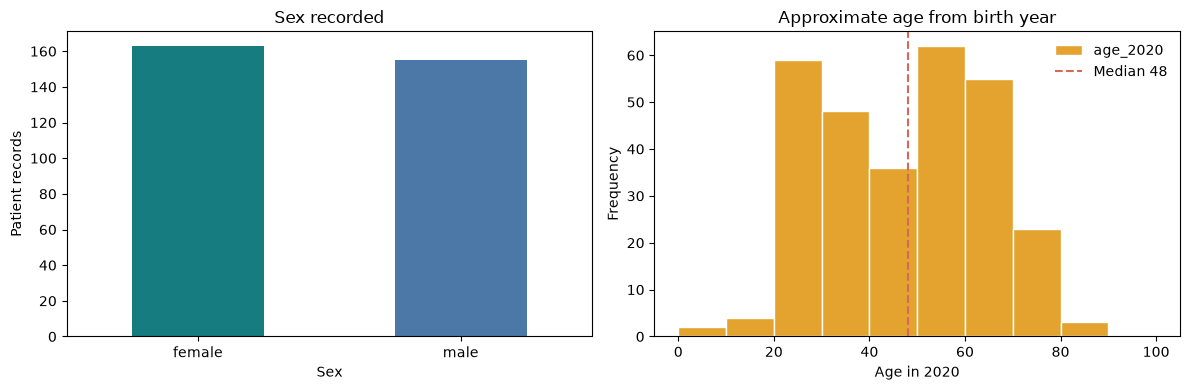

In [3]:
print('Sex counts among records with sex recorded:')
display(df['sex'].value_counts().rename_axis('sex').to_frame('records'))
print('Approximate age summary:')
display(df['age_2020'].describe().to_frame('age_2020'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['sex'].value_counts().reindex(['female', 'male']).dropna().plot(kind='bar', ax=axes[0], color=['#167C80', '#4C78A8'])
axes[0].set_title('Sex recorded')
axes[0].set_xlabel('Sex')
axes[0].set_ylabel('Patient records')
axes[0].tick_params(axis='x', rotation=0)
df['age_2020'].dropna().plot(kind='hist', bins=np.arange(0, 101, 10), ax=axes[1], color='#E3A32E', edgecolor='white')
axes[1].axvline(df['age_2020'].median(), color='#D46A55', linestyle='--', label=f"Median {df['age_2020'].median():.0f}")
axes[1].set_title('Approximate age from birth year')
axes[1].set_xlabel('Age in 2020')
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'demographics.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Confirmation-date pattern

Records confirmed from 27 February to 1 March: 2,951 (70.1%)


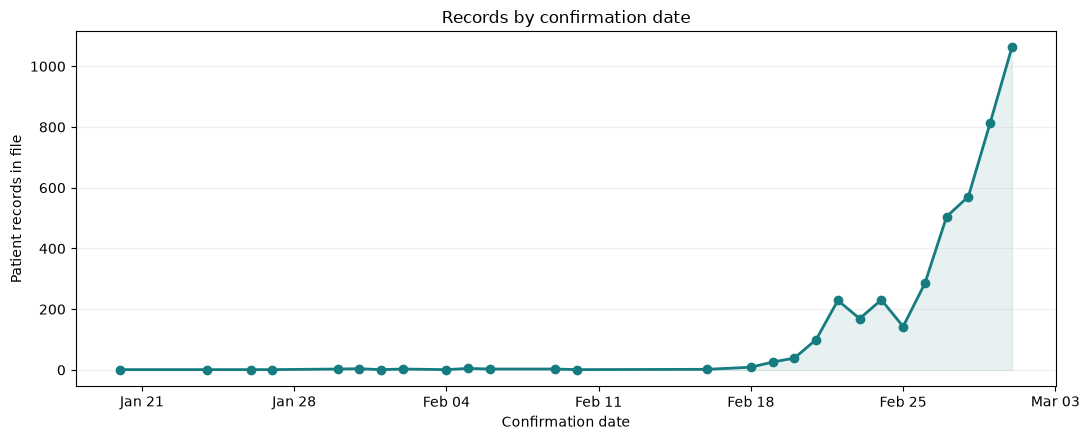

In [4]:
daily = df.groupby(df['confirmed_date'].dt.normalize()).size().sort_index()
recent = df.loc[df['confirmed_date'].ge('2020-02-27')].shape[0]
print(f'Records confirmed from 27 February to 1 March: {recent:,} ({recent / len(df):.1%})')
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily.index, daily.values, marker='o', color='#167C80', linewidth=2)
ax.fill_between(daily.index, daily.values, color='#167C80', alpha=.10)
ax.set_title('Records by confirmation date')
ax.set_ylabel('Patient records in file')
ax.set_xlabel('Confirmation date')
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(FIG_DIR / 'confirmation_trend.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Infection reasons and regions

Known infection reasons: 130


,records
infection_reason,
contact with patient,66
visit to Daegu,40
visit to Wuhan,8
pilgrimage to Israel,6
residence in Wuhan,2
visit to Thailand,2
contact with patient in Singapore,2
contact with patient in Japan,1
visit to China,1


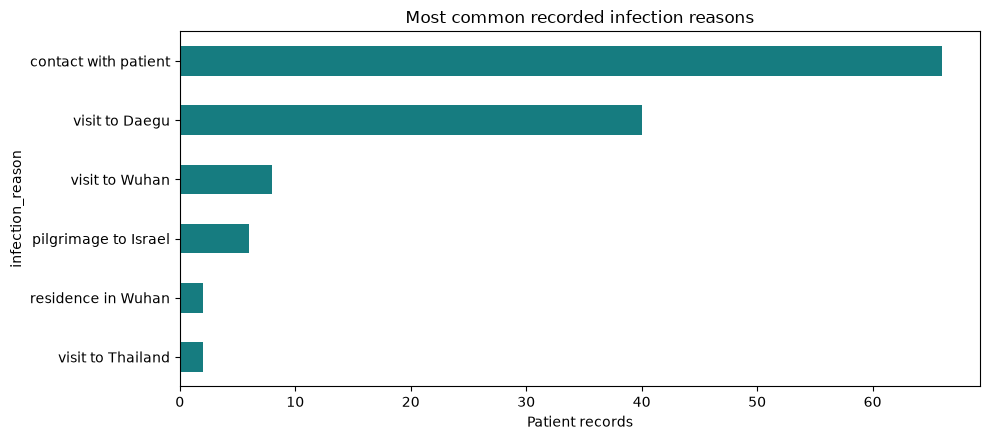

state,isolated,released,deceased
region,,,
Gyeongsangbuk-do,110,1,8
capital area,92,16,1
Daegu,29,2,3
Gwangju,7,3,0
Daejeon,10,0,0
Gangwon-do,5,0,0


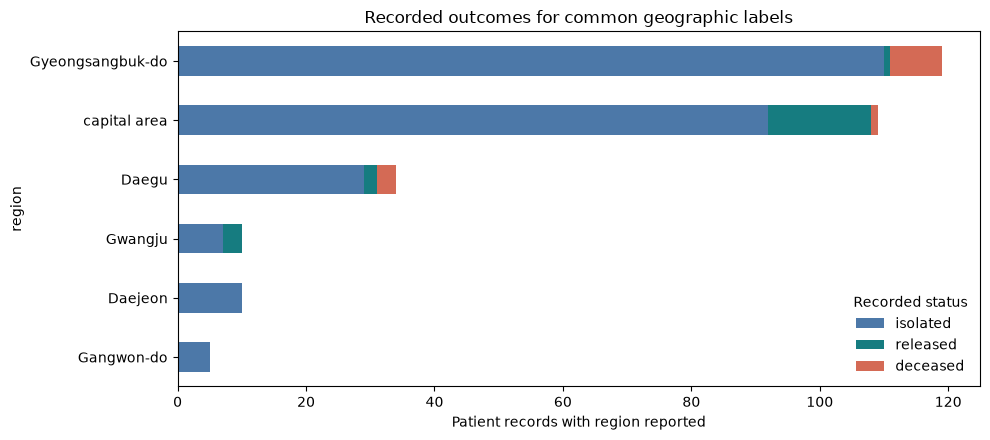

In [5]:
reason_counts = df['infection_reason'].value_counts().dropna()
print('Known infection reasons:', int(df['infection_reason'].notna().sum()))
display(reason_counts.head(10).rename_axis('infection_reason').to_frame('records'))
top_reasons = reason_counts.head(6).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
top_reasons.plot(kind='barh', ax=ax, color='#167C80')
ax.set_title('Most common recorded infection reasons')
ax.set_xlabel('Patient records')
fig.tight_layout()
fig.savefig(FIG_DIR / 'infection_reasons.png', dpi=180, bbox_inches='tight')
plt.show()

region_counts = df['region'].value_counts().dropna().drop(labels=['filtered at airport'], errors='ignore')
top_regions = region_counts.head(6).index
region_outcomes = pd.crosstab(df['region'], df['state']).reindex(top_regions).fillna(0)
for state in ['isolated', 'released', 'deceased']:
    if state not in region_outcomes.columns:
        region_outcomes[state] = 0
region_outcomes = region_outcomes[['isolated', 'released', 'deceased']]
display(region_outcomes)
ax = region_outcomes.plot(kind='barh', stacked=True, figsize=(10, 4.5), color=['#4C78A8', '#167C80', '#D46A55'])
ax.set_title('Recorded outcomes for common geographic labels')
ax.set_xlabel('Patient records with region reported')
ax.invert_yaxis()
ax.legend(title='Recorded status', frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / 'regions_and_outcomes.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Recovery duration and exploratory factors

Released records with both dates: 28


,days_to_release
count,28.000000
mean,15.107143
std,5.626256
min,7.000000
25%,9.750000
50%,16.000000
75%,19.250000
max,24.000000


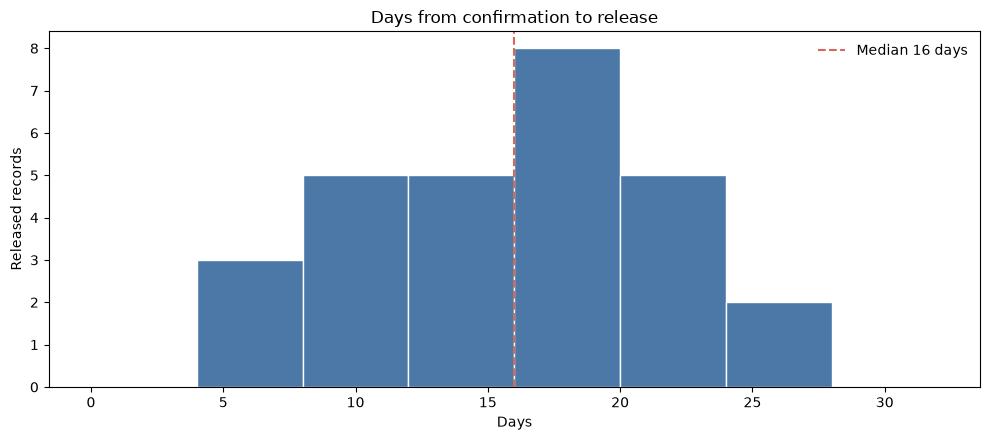

,variable,n,spearman_rho
0,age_2020,28,-0.060465
1,infection_order,24,0.036751
2,contact_number,24,-0.210653


In [6]:
released = df.loc[df['state'].eq('released')].copy()
durations = released['recovery_days'].dropna()
print('Released records with both dates:', len(durations))
display(durations.describe(percentiles=[.25, .5, .75]).to_frame('days_to_release'))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(durations, bins=np.arange(0, 36, 4), color='#4C78A8', edgecolor='white')
ax.axvline(durations.median(), color='#D46A55', linestyle='--', label=f'Median {durations.median():.0f} days')
ax.set_title('Days from confirmation to release')
ax.set_xlabel('Days')
ax.set_ylabel('Released records')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'recovery_duration.png', dpi=180, bbox_inches='tight')
plt.show()

def spearman_rho(frame, column):
    pair = frame[[column, 'recovery_days']].dropna()
    rho = pair[column].rank(method='average').corr(pair['recovery_days'].rank(method='average'))
    return len(pair), rho

rows = []
for column in ['age_2020', 'infection_order', 'contact_number']:
    count, rho = spearman_rho(released, column)
    rows.append({'variable': column, 'n': count, 'spearman_rho': rho})
associations = pd.DataFrame(rows)
display(associations)

## 7. Findings and limitations

- The file contains 4,212 patient records, with confirmation dates from 20 January through 1 March 2020.
- The recorded confirmation dates cluster at the end of February; this is a pattern in this patient file, not the official national case-count series.
- The most frequent known infection reasons are contact with a patient (66) and visit to Daegu (40), but 96.9% of infection-reason values are missing.
- The median time to release is 16 days for the 28 records with both dates.
- The rank correlations are exploratory. The small number of resolved cases and missing predictors do not support a reliable linear regression or causal conclusion.

For stronger conclusions, repeat the analysis with a more complete and consistently updated patient dataset. The notebook uses only the included CSV and does not fetch data from the internet.